# Alignement par préférences (DPO)

Le DPO part du modèle obtenu après le SFT. Chaque paire du jeu donne une question, une réponse préférée et une réponse rejetée : on rend la réponse préférée plus probable et la rejetée moins probable, en comparant avec le modèle SFT, qui reste figé et sert de référence.

Les paires viennent d'UltraMedical-Preference (en anglais, préférences choisies par GPT-4) : 3 000 pour l'entraînement et 300 pour la validation, préparées à l'étape 1.

Mêmes outils que pour le SFT : TRL (`DPOTrainer`), PEFT pour LoRA, MLflow. Même démarche : un petit run, puis deux runs complets, et on garde le meilleur checkpoint sur la validation.

In [1]:
import gc
import json
import shutil
import statistics
import time
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import torch
from datasets import load_dataset
from peft import LoraConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import DPOConfig, DPOTrainer

SEED = 42
MODEL = "Qwen/Qwen3-1.7B-Base"
DATA_REPO, DATA_REVISION = "g-hostin/medical-triage-poc-data", "v1.1"
SFT_DIR = Path("../models/sft/final")
OUT_DIR = Path("../models/dpo")

set_seed(SEED)
mlflow.set_tracking_uri("sqlite:///../mlflow.db")
mlflow.set_experiment("dpo")
tokenizer = AutoTokenizer.from_pretrained(MODEL)
print(json.loads((SFT_DIR / "run_info.json").read_text(encoding="utf-8"))["name"], "retenu au SFT")

C:\Users\gregh\Desktop\OpenClassrooms\AI Engineer\P14\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


run1_lr2e-4 retenu au SFT


## 1. Les données

Même format qu'au SFT : la question avec le gabarit de conversation, les réponses en texte simple. TRL ajoute `<|endoftext|>` à la fin des deux réponses.

In [2]:
dpo = load_dataset(DATA_REPO, "dpo", revision=DATA_REVISION)


def to_strings(row):
    return {"prompt": tokenizer.apply_chat_template(row["prompt"], tokenize=False, add_generation_prompt=True),
            "chosen": row["chosen"][0]["content"], "rejected": row["rejected"][0]["content"]}


columns = ["prompt", "chosen", "rejected"]
train_ds = dpo["train"].select_columns(columns).map(to_strings).shuffle(seed=SEED)
val_ds = dpo["validation"].select_columns(columns).map(to_strings).select(range(100))  # 100 sur 300 : une évaluation sur 300 prend trop de temps sur notre carte
print("entraînement :", len(train_ds), "| validation :", len(val_ds))

lengths = [len(tokenizer(r["prompt"] + max(r["chosen"], r["rejected"], key=len)).input_ids) + 1 for r in train_ds]
print("longueur en tokens (question + réponse la plus longue) : médiane", int(statistics.median(lengths)), "| max", max(lengths))

entraînement : 3000 | validation : 100


longueur en tokens (question + réponse la plus longue) : médiane 567 | max 1033


On fixe la longueur maximale au-dessus du maximum mesuré, pour ne couper aucune réponse.

## 2. Le modèle de départ

On charge le modèle de base, on lui ajoute l'adaptateur LoRA du SFT, puis on fusionne les deux (`merge_and_unload`) : on obtient un modèle SFT ordinaire. Le DPO lui ajoute un nouvel adaptateur LoRA. Pour calculer la référence, TRL désactive cet adaptateur : la référence est donc exactement le modèle SFT, sans charger un second modèle en mémoire.

In [3]:
MAX_LENGTH = 1152
LORA = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")


def load_sft_model():
    base = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16)
    return PeftModel.from_pretrained(base, SFT_DIR).merge_and_unload()


def train_run(name, train_data, val_data, learning_rate, epochs=1, beta=0.1, eval_steps=125):
    model = load_sft_model()
    args = DPOConfig(
        output_dir=str(OUT_DIR / name),
        run_name=name,
        beta=beta,  # plus beta est grand, plus le modèle reste près de la référence
        max_length=MAX_LENGTH,
        per_device_train_batch_size=1,  # avec 2 paires à la fois, la mémoire de la carte débordait (18 s par pas)
        gradient_accumulation_steps=8,
        per_device_eval_batch_size=1,  # au-delà, la mémoire de la carte déborde pendant l'évaluation
        torch_empty_cache_steps=10,  # rend régulièrement la mémoire gardée en réserve par PyTorch
        learning_rate=learning_rate,
        num_train_epochs=epochs,
        warmup_steps=20,
        logging_steps=10,
        eval_strategy="steps",
        eval_steps=eval_steps,
        save_strategy="steps",
        save_steps=eval_steps,
        save_total_limit=2,
        load_best_model_at_end=True,
        seed=SEED,
        report_to="mlflow",
    )
    trainer = DPOTrainer(model=model, args=args, train_dataset=train_data, eval_dataset=val_data,
                         processing_class=tokenizer, peft_config=LORA)
    torch.cuda.reset_peak_memory_stats()
    start = time.time()
    with mlflow.start_run(run_name=name):
        mlflow.log_params({"dataset": DATA_REPO, "dataset_revision": DATA_REVISION, "n_train": len(train_data),
                           "n_val": len(val_data), "lora_r": LORA.r, "lora_alpha": LORA.lora_alpha,
                           "sft_model": json.loads((SFT_DIR / "run_info.json").read_text(encoding="utf-8"))["name"]})
        # en cas d'arrêt, trainer.train(resume_from_checkpoint=True) reprend au dernier checkpoint
        trainer.train()
    trainer.save_model(OUT_DIR / name / "best")
    best_eval = [h for h in trainer.state.log_history if h.get("eval_loss") == trainer.state.best_metric][0]
    summary = {"name": name, "learning_rate": learning_rate, "beta": beta, "epochs": epochs,
               "best_checkpoint": Path(trainer.state.best_model_checkpoint).name,
               "best_eval_loss": trainer.state.best_metric,
               "best_eval_accuracy": best_eval["eval_rewards/accuracies"],
               "minutes": (time.time() - start) / 60, "memory_gb": torch.cuda.max_memory_allocated() / 1e9,
               "history": trainer.state.log_history}
    print(f"{name} : {summary['minutes']:.1f} min, mémoire max {summary['memory_gb']:.1f} Go")
    print(f"meilleur checkpoint : {summary['best_checkpoint']}, perte de validation {summary['best_eval_loss']:.3f}, "
          f"paires bien rangées {summary['best_eval_accuracy']:.0%}")
    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()
    print(f"mémoire encore occupée par PyTorch : {torch.cuda.memory_reserved() / 1e9:.1f} Go")
    return summary

## 3. Petit run

48 paires d'entraînement et 20 de validation. Au début, le modèle entraîné et la référence sont identiques : la perte vaut 0,69 (ln 2). TRL suit aussi `rewards/accuracies`, la part des paires où le modèle a plus rapproché la réponse préférée que la rejetée par rapport à la référence.

In [4]:
small_train, small_val = train_ds.select(range(48)), val_ds.select(range(20))
small = train_run("petit_run", small_train, small_val, learning_rate=5e-5, eval_steps=3)
print([(h["step"], round(h["eval_loss"], 3), round(h["eval_rewards/accuracies"], 2))
       for h in small["history"] if "eval_loss" in h])

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   3%|▎         | 9/310 [00:00<00:03, 83.89it/s]

Loading weights:   6%|▌         | 18/310 [00:00<00:03, 78.20it/s]

Loading weights:   8%|▊         | 26/310 [00:00<00:05, 53.80it/s]

Loading weights:  10%|█         | 32/310 [00:00<00:05, 47.65it/s]

Loading weights:  13%|█▎        | 40/310 [00:00<00:04, 55.76it/s]

... (15 outputs left out)

Dropping fully truncated examples from eval dataset:   0%|          | 0/20 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset: 100%|██████████| 20/20 [00:00<00:00, 2216.45 examples/s]

Step,Training Loss,Validation Loss,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
3,No log,0.711027,0.950593,25988.000000,5.134159,5.293170,0.712586,0.019375,0.047800,0.400000,-0.028425,-433.197270,-329.667024
6,No log,0.723849,0.950750,52879.000000,5.130476,5.297239,0.712557,-0.001849,0.052730,0.300000,-0.054579,-433.409513,-329.617728


petit_run : 0.7 min, mémoire max 6.0 Go
meilleur checkpoint : checkpoint-3, perte de validation 0.711, paires bien rangées 40%
mémoire encore occupée par PyTorch : 0.0 Go
[(3, 0.711, 0.4), (6, 0.724, 0.3)]


La chaîne tourne. Sur 48 paires (6 pas), le modèle n'a pas le temps d'apprendre : la perte de validation reste près de 0,69 (0,711 puis 0,724), et la part de paires bien rangées sur 20 paires de validation (40 % puis 30 %) ne veut rien dire avec si peu d'exemples.

Lors des premiers essais, avec deux paires à la fois et les 300 paires de validation, la mémoire de la carte débordait et chaque pas prenait environ 18 s. D'où une paire à la fois, 100 paires de validation et la mémoire rendue tous les 10 pas.

## 4. Run complet

Une époque sur les 3 000 paires, avec un learning rate de 5e-5. Le notebook Unsloth utilise 5e-6 sur trois époques ; avec une seule époque, on prend un learning rate plus fort. Un second run avec 5e-6 suit, pour comparer.

In [5]:
run1 = train_run("run_lr5e-5", train_ds, val_ds, learning_rate=5e-5)

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   3%|▎         | 9/310 [00:00<00:03, 84.04it/s]

Loading weights:   6%|▌         | 18/310 [00:00<00:04, 65.39it/s]

Loading weights:   8%|▊         | 25/310 [00:00<00:06, 42.06it/s]

Loading weights:  10%|▉         | 30/310 [00:00<00:06, 42.51it/s]

Loading weights:  11%|█▏        | 35/310 [00:00<00:07, 35.73it/s]

... (56 outputs left out)

Dropping fully truncated examples from eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset: 100%|██████████| 100/100 [00:00<00:00, 9084.28 examples/s]

Step,Training Loss,Validation Loss,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
125,0.522320,0.581497,1.035227,1094587.000000,5.555527,5.752984,0.717699,1.324581,0.069880,0.700000,1.254701,-436.455543,-304.711148
250,0.356591,0.531770,1.021755,2178427.000000,5.385702,5.539902,0.716624,0.851127,-0.911238,0.770000,1.762366,-441.190077,-314.522328
375,0.367259,0.582031,1.051038,3272430.000000,5.446108,5.586305,0.715926,0.602938,-1.229617,0.760000,1.832555,-443.671968,-317.706116


run_lr5e-5 : 49.5 min, mémoire max 6.1 Go
meilleur checkpoint : checkpoint-250, perte de validation 0.532, paires bien rangées 77%
mémoire encore occupée par PyTorch : 0.0 Go


### Second run : learning rate 5e-6

Mêmes données et mêmes réglages que le run 1, une seule époque : seul le learning rate change. Avec des corrections dix fois plus petites, le modèle devrait moins s'éloigner de la référence.

In [5]:
run2 = train_run("run_lr5e-6", train_ds, val_ds, learning_rate=5e-6)

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   4%|▍         | 12/310 [00:00<00:03, 92.27it/s]

Loading weights:   7%|▋         | 22/310 [00:00<00:05, 49.10it/s]

Loading weights:   9%|▉         | 28/310 [00:00<00:05, 48.65it/s]

Loading weights:  11%|█         | 34/310 [00:00<00:06, 42.01it/s]

Loading weights:  13%|█▎        | 39/310 [00:00<00:06, 39.45it/s]

... (9 outputs left out)

Dropping fully truncated examples from eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset: 100%|██████████| 100/100 [00:00<00:00, 9515.86 examples/s]

Step,Training Loss,Validation Loss,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
125,0.604873,0.623966,0.928190,1094587.000000,5.132263,5.272476,0.715897,0.402791,0.050355,0.720000,0.352436,-445.673445,-304.906397
250,0.496911,0.635606,0.943012,2178427.000000,5.191926,5.310700,0.717292,0.587308,-0.051078,0.710000,0.638386,-443.828271,-305.920728
375,0.492128,0.641648,0.947478,3272430.000000,5.205760,5.321284,0.718117,0.636348,-0.072521,0.720000,0.708869,-443.337875,-306.135161


run_lr5e-6 : 45.7 min, mémoire max 6.1 Go
meilleur checkpoint : checkpoint-125, perte de validation 0.624, paires bien rangées 72%
mémoire encore occupée par PyTorch : 0.0 Go


## 5. Courbes de validation

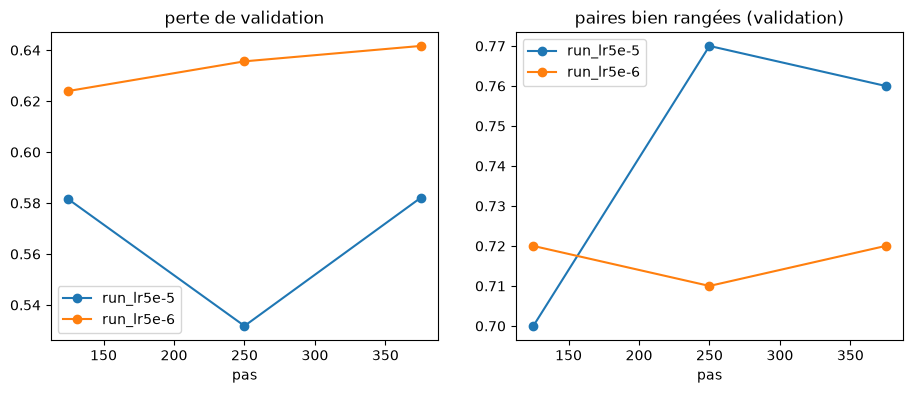

run_lr5e-5 : perte de validation 0.532, paires bien rangées 77% (checkpoint-250), 50 min
run_lr5e-6 : perte de validation 0.624, paires bien rangées 72% (checkpoint-125), 46 min


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for run, color in ((run1, "tab:blue"), (run2, "tab:orange")):
    evals = [h for h in run["history"] if "eval_loss" in h]
    steps = [h["step"] for h in evals]
    axes[0].plot(steps, [h["eval_loss"] for h in evals], marker="o", color=color, label=run["name"])
    axes[1].plot(steps, [h["eval_rewards/accuracies"] for h in evals], marker="o", color=color, label=run["name"])
axes[0].set_title("perte de validation")
axes[1].set_title("paires bien rangées (validation)")
for ax in axes:
    ax.set_xlabel("pas")
    ax.legend()
plt.show()

for run in (run1, run2):
    print(f"{run['name']} : perte de validation {run['best_eval_loss']:.3f}, paires bien rangées "
          f"{run['best_eval_accuracy']:.0%} ({run['best_checkpoint']}), {run['minutes']:.0f} min")

Pour le run à 5e-5, la perte de validation baisse jusqu'au pas 250 (0,532), puis remonte au pas 375 (0,582). La part de paires bien rangées suit : 70 % au pas 125, 77 % au pas 250, 76 % au pas 375. La remontée en fin d'époque est un début de sur-apprentissage : on garde le checkpoint 250, que `load_best_model_at_end` a rechargé.

Le run à 5e-6 reste derrière à chaque relevé : au mieux 0,624 de perte de validation et 72 % de paires bien rangées (checkpoint 125), contre 0,532 et 77 % pour le run à 5e-5. Sur une seule époque, des corrections dix fois plus petites laissent le modèle trop près de la référence. Le notebook Unsloth compense avec trois époques, soit trois fois plus de temps sur notre carte. On garde le run à 5e-5.

In [7]:
best = min((run1, run2), key=lambda run: run["best_eval_loss"])
final_dir = OUT_DIR / "final"
shutil.copytree(OUT_DIR / best["name"] / "best", final_dir, dirs_exist_ok=True)
tokenizer.save_pretrained(final_dir)
info = {key: value for key, value in best.items() if key != "history"}
info.update({"model": MODEL, "start": "SFT fusionné (" + str(SFT_DIR) + ")", "dataset": DATA_REPO,
             "dataset_revision": DATA_REVISION, "seed": SEED,
             "lora": {"r": LORA.r, "alpha": LORA.lora_alpha, "dropout": LORA.lora_dropout}})
(final_dir / "run_info.json").write_text(json.dumps(info, indent=2, ensure_ascii=False), encoding="utf-8")
print("retenu :", best["name"], "->", final_dir)

retenu : run_lr5e-5 -> ..\models\dpo\final


## 6. Vérification rapide

Le DPO est fait sur des questions en anglais. On vérifie que le modèle répond toujours au format du triage, en français, et qu'il s'arrête seul. La mesure complète se fait dans le notebook 06.

In [8]:
model = PeftModel.from_pretrained(load_sft_model().to("cuda"), final_dir).eval()
end_of_text = tokenizer.convert_tokens_to_ids("<|endoftext|>")
triage_val = load_dataset(DATA_REPO, "triage", revision=DATA_REVISION, split="train").shuffle(seed=SEED).select(range(2))
questions = [r["messages"][0]["content"] for r in triage_val] + [dpo["validation"][0]["prompt"][0]["content"]]

for question in questions:
    prompt = tokenizer.apply_chat_template([{"role": "user", "content": question}], tokenize=False, add_generation_prompt=True)
    ids = tokenizer(prompt, return_tensors="pt").input_ids.to("cuda")
    with torch.no_grad():
        out = model.generate(ids, max_new_tokens=500, do_sample=False)
    new_tokens = out[0, ids.shape[1]:]
    print(question[:150].replace("\n", " "), "[...]")
    print("modèle :", tokenizer.decode(new_tokens, skip_special_tokens=True)[:400])
    print(f"s'arrête seul : {'oui' if new_tokens[-1].item() == end_of_text else 'non'} ({len(new_tokens)} tokens)\n")

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   2%|▏         | 7/310 [00:00<00:04, 66.87it/s]

Loading weights:   5%|▍         | 14/310 [00:00<00:05, 50.75it/s]

Loading weights:   6%|▋         | 20/310 [00:00<00:06, 45.52it/s]

Loading weights:   8%|▊         | 25/310 [00:00<00:06, 42.86it/s]

Loading weights:  10%|▉         | 30/310 [00:00<00:06, 41.05it/s]

... (7 outputs left out)

Loading weights: 100%|██████████| 310/310 [00:01<00:00, 172.81it/s]

Cas clinique : Une femme de 62 ans est hospitalisée pour bilan d'un diabète récemment découvert. L'interrogatoire retrouve comme antécédents pathologi [...]
modèle : Niveau : urgence modérée (tri 3B de l'échelle FRENCH).
Explication : La patiente de 62 ans consulte pour des lésions cutanées de la région périnéale et sous-mammaire, érythémateuses, luisantes, prédominant au fond des plis, avec collerette desquamative, pustules blanchâtres et prurit, évoluant depuis quelques semaines. Le motif « Lésion cutanée » a un tri par défaut 3B, et le prurit est un critère
s'arrête seul : oui (343 tokens)



Cas clinique : Cet homme de 76 ans, ancien chauffeur, est atteint depuis un an d'une leucémie lymphoïde chronique qui fait l'objet d'une simple survei [...]
modèle : Niveau : urgence maximale (tri 2 de l'échelle FRENCH).
Explication : Homme de 76 ans consultant pour une diarrhée fébrile à 40 °C depuis 4 jours, avec douleurs abdominales, signes de déshydratation (sécheresse des aisselles, langue saburrale, abdomen gargouillant) et polyadénopathies superficielles, évoquant une septicémie. Le motif « Fièvre » a un tri par défaut 3B, mais le critère « fièvre > 40 
s'arrête seul : oui (288 tokens)



A 17-year-old girl presents with significant weight loss over the last few months. There is a positive family history of Hodgkin lymphoma and hyperthy [...]
modèle : Answer: A, amenorrhea
s'arrête seul : oui (8 tokens)



## Bilan

- run retenu : learning rate 5e-5, une époque, checkpoint 250, perte de validation 0,532 et 77 % des paires de validation bien rangées. Adaptateur dans `models/dpo/final`, réglages dans `run_info.json`, courbes dans MLflow (expérience `dpo`)
- 49,5 min sur la carte, une paire à la fois
- second run à 5e-6 : derrière à chaque relevé (au mieux 0,624 et 72 %), 46 min
- après le DPO, le modèle répond toujours au format du triage en français et s'arrête seul sur les cas vérifiés
- l'effet sur le triage, les QCM et les préférences des experts se mesure dans le notebook 06
- limites : préférences en anglais choisies par GPT-4, validation réduite à 100 paires, une seule époque par run